In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")

In [2]:
df = pd.read_csv(r"C:\Users\VMR\Downloads\online_gaming_behavior_dirty_dataset.csv")
df.head()

,user_id,age,gender,region,avg_daily_play_hours,preferred_game_type,uses_public_wifi,monthly_spend_inr,government_internet_scheme,reported_health_issues,academic_or_work_impact
0,1,48,M,Urban,0.25,Sports,No,1858.70,Yes,Yes,Low
1,2,NaN,Male,Urban,2.39,Puzzle,NaN,3435.10,NaN,NaN,Low
2,3,38,Female,Rural,6.50,Strategy,N,3132.96,NaN,NaN,Medium
3,4,24,Female,NaN,2.33,Battle Royale,Y,2461.63,NaN,NaN,Severe
4,5,52,Male,Urban,3.10,Simulation,Y,4459.36,Don't Know,No,Severe


In [3]:
df.shape

(500, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     500 non-null    int64  
 1   age                         476 non-null    object 
 2   gender                      424 non-null    object 
 3   region                      411 non-null    object 
 4   avg_daily_play_hours        495 non-null    float64
 5   preferred_game_type         428 non-null    object 
 6   uses_public_wifi            390 non-null    object 
 7   monthly_spend_inr           498 non-null    float64
 8   government_internet_scheme  380 non-null    object 
 9   reported_health_issues      370 non-null    object 
 10  academic_or_work_impact     395 non-null    object 
dtypes: float64(2), int64(1), object(8)
memory usage: 43.1+ KB


In [5]:
df.describe()

,user_id,avg_daily_play_hours,monthly_spend_inr
count,500.000000,495.000000,498.000000
mean,250.500000,5.312929,2609.935803
std,144.481833,3.103263,1443.003636
min,1.000000,-1.000000,-100.000000
25%,125.750000,2.580000,1502.017500
50%,250.500000,6.080000,2476.275000
75%,375.250000,7.800000,3844.610000
max,500.000000,9.980000,4989.100000


In [6]:
df.isnull().sum()

user_id                         0
age                            24
gender                         76
region                         89
avg_daily_play_hours            5
preferred_game_type            72
uses_public_wifi              110
monthly_spend_inr               2
government_internet_scheme    120
reported_health_issues        130
academic_or_work_impact       105
dtype: int64

In [7]:
(df == "").sum()

user_id                       0
age                           0
gender                        0
region                        0
avg_daily_play_hours          0
preferred_game_type           0
uses_public_wifi              0
monthly_spend_inr             0
government_internet_scheme    0
reported_health_issues        0
academic_or_work_impact       0
dtype: int64

In [8]:
df.replace("",np.nan, inplace=True)

In [9]:
df["gender"] = df["gender"].replace({
    "M": "Male",
    "F": "Female"
})

In [10]:
yes_no_map = {
    "Y": "Yes",
    "N": "No"
}

df["uses_public_wifi"] = df["uses_public_wifi"].replace(yes_no_map)

In [11]:
df["region"] = df["region"].replace("URBAN", "Urban")

In [12]:
df.loc[df["avg_daily_play_hours"] < 0, "avg_daily_play_hours"] = np.nan
df.loc[df["monthly_spend_inr"] < 0, "monthly_spend_inr"] = np.nan

In [13]:
df["avg_daily_play_hours"] = df["avg_daily_play_hours"].fillna(
    df["avg_daily_play_hours"].median()
)

df["monthly_spend_inr"] = df["monthly_spend_inr"].fillna(
    df["monthly_spend_inr"].median()
)


In [14]:
categorical_cols = [
    "gender", "region", "preferred_game_type",
    "uses_public_wifi", "government_internet_scheme",
    "reported_health_issues", "academic_or_work_impact"
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [15]:
df["age"].unique()

array(['48', nan, '38', '24', '52', '17', '30', '28', '32', '20', '33',
       'unknown', '45', '49', '12', '31', '11', '53', '39', '47', '42',
       '21', '34', '58', '36', '51', '37', '25', '56', '46', '16', '18',
       '27', '13', '23', '59', '35', '29', '44', '26', '15', '43', '19',
       '40', '57', '54', '50', '10', '14', '22', '41', '55'], dtype=object)

In [16]:
df["age"] = pd.to_numeric(df["age"], errors="coerce")

In [17]:
df["age"] = df["age"].fillna(df["age"].median())

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     500 non-null    int64  
 1   age                         500 non-null    float64
 2   gender                      500 non-null    object 
 3   region                      500 non-null    object 
 4   avg_daily_play_hours        500 non-null    float64
 5   preferred_game_type         500 non-null    object 
 6   uses_public_wifi            500 non-null    object 
 7   monthly_spend_inr           500 non-null    float64
 8   government_internet_scheme  500 non-null    object 
 9   reported_health_issues      500 non-null    object 
 10  academic_or_work_impact     500 non-null    object 
dtypes: float64(3), int64(1), object(7)
memory usage: 43.1+ KB


In [19]:
df.isnull().sum()

user_id                       0
age                           0
gender                        0
region                        0
avg_daily_play_hours          0
preferred_game_type           0
uses_public_wifi              0
monthly_spend_inr             0
government_internet_scheme    0
reported_health_issues        0
academic_or_work_impact       0
dtype: int64

In [20]:
df[["avg_daily_play_hours", "monthly_spend_inr"]].describe()

,avg_daily_play_hours,monthly_spend_inr
count,500.000000,500.000000
mean,5.377240,2624.930860
std,3.036569,1424.674657
min,0.060000,21.820000
25%,2.667500,1564.885000
50%,6.080000,2483.480000
75%,7.800000,3844.610000
max,9.980000,4989.100000


In [21]:
df["avg_daily_play_hours"].mean(), df["avg_daily_play_hours"].median(), df["avg_daily_play_hours"].mode()

(np.float64(5.37724),
 6.08,
 0    6.08
 Name: avg_daily_play_hours, dtype: float64)

In [22]:
df["monthly_spend_inr"].skew()

np.float64(-0.06142866569551293)

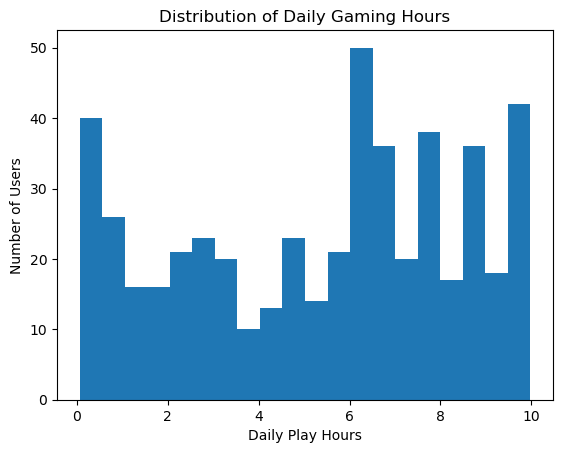

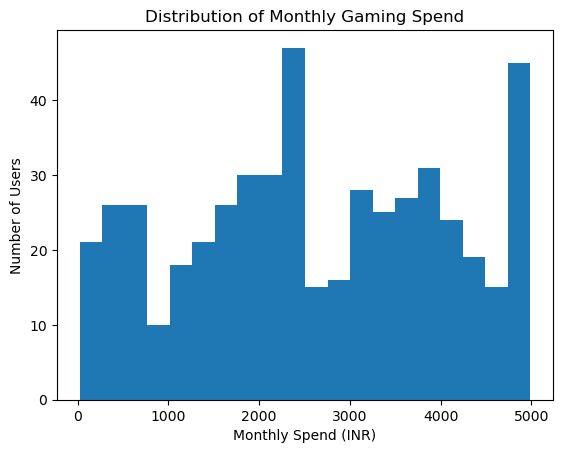

In [23]:
plt.hist(df["avg_daily_play_hours"], bins=20)
plt.xlabel("Daily Play Hours")
plt.ylabel("Number of Users")
plt.title("Distribution of Daily Gaming Hours")
plt.show()
plt.hist(df["monthly_spend_inr"], bins=20)
plt.xlabel("Monthly Spend (INR)")
plt.ylabel("Number of Users")
plt.title("Distribution of Monthly Gaming Spend")
plt.show()


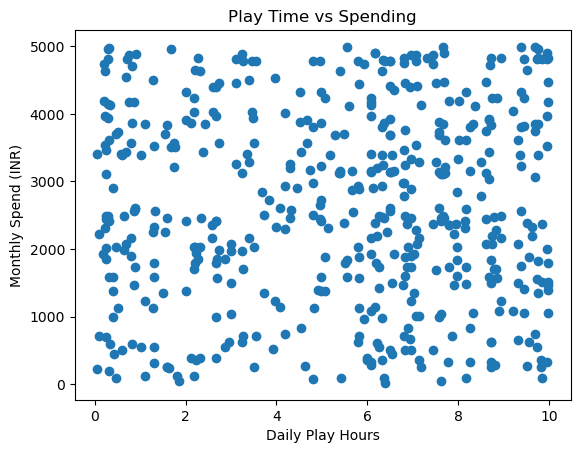

In [24]:
plt.scatter(df["avg_daily_play_hours"], df["monthly_spend_inr"])
plt.xlabel("Daily Play Hours")
plt.ylabel("Monthly Spend (INR)")
plt.title("Play Time vs Spending")
plt.show()

In [25]:
df.head()

,user_id,age,gender,region,avg_daily_play_hours,preferred_game_type,uses_public_wifi,monthly_spend_inr,government_internet_scheme,reported_health_issues,academic_or_work_impact
0,1,48.0,Male,Urban,0.25,Sports,No,1858.70,Yes,Yes,Low
1,2,35.0,Male,Urban,2.39,Puzzle,Yes,3435.10,Yes,Sometimes,Low
2,3,38.0,Female,Rural,6.50,Strategy,No,3132.96,Yes,Sometimes,Medium
3,4,24.0,Female,Urban,2.33,Battle Royale,Yes,2461.63,Yes,Sometimes,Severe
4,5,52.0,Male,Urban,3.10,Simulation,Yes,4459.36,Don't Know,No,Severe


In [26]:
df.to_csv("online_gaming_behavior_cleaned.csv", index=False)